# 01 — Prepare the SciTLDR-A dataset

**Purpose:** download SciTLDR-A, normalize its text, check the official splits, remove cross-split abstract duplicates, inspect reference counts and token lengths, and save processed JSONL files.

**Input:** `configs/config.yaml`  
**Outputs:** `data/raw/*.jsonl` and `data/processed/{train,val,test}.jsonl`

Run this notebook first, from the project root or from the `notebooks/` folder. The source split named `dev` is saved as `val` (validation). The training split is expected to have one TLDR per paper; validation and test references are all preserved.


In [1]:
from pathlib import Path
import json, re, urllib.request
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from transformers import AutoTokenizer
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CFG = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text())
D = CFG["data"]
RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
RAW.mkdir(parents=True, exist_ok=True)
PROC.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("SciTLDR source:", D["url"])


Project root: c:\Users\admin\Downloads\scitldr-hallucination\scitldr-hallucination
SciTLDR source: https://raw.githubusercontent.com/allenai/scitldr/master/SciTLDR-Data/SciTLDR-A


## 1. Download and read the official splits

The official `dev` split is used as validation. Whitespace is normalized, but the abstract and all human TLDR references are otherwise retained.


In [2]:
def clean(text):
    return re.sub(r"\\s+", " ", text or "").strip()

rename_split = {"dev": "val"}
rows = []

for official_split in ("train", "dev", "test"):
    path = RAW / f"{official_split}.jsonl"
    if not path.exists():
        url = f"{D['url']}/{official_split}.jsonl"
        print("Downloading", url)
        urllib.request.urlretrieve(url, path)

    with path.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            record = json.loads(line)
            rows.append({
                "split": rename_split.get(official_split, official_split),
                "id": str(record["paper_id"]),
                "abstract": clean(" ".join(record["source"])),
                "human_tldrs": [clean(t) for t in record["target"] if clean(t)]
            })

papers = pd.DataFrame(rows)
papers["n_refs"] = papers["human_tldrs"].str.len()
papers["abstract_words"] = papers["abstract"].str.split().str.len()
papers["first_tldr_words"] = papers["human_tldrs"].str[0].str.split().str.len()

display(papers.groupby("split").agg(
    papers=("id", "size"),
    references=("n_refs", "sum"),
    mean_refs_per_paper=("n_refs", "mean"),
    mean_abstract_words=("abstract_words", "mean"),
    mean_first_tldr_words=("first_tldr_words", "mean")
).round(2))


,papers,references,mean_refs_per_paper,mean_abstract_words,mean_first_tldr_words
split,,,,,
test,618,1967,3.18,162.05,18.85
train,1992,1992,1.00,158.74,19.27
val,619,1453,2.35,159.03,18.96


## 2. Validate the raw data

These checks apply before duplicate removal, so the counts should match the official counts in the config.


In [3]:
raw_counts = papers.groupby("split").size().to_dict()
expected = {"train": D["sizes"]["train"], "val": D["sizes"]["dev"], "test": D["sizes"]["test"]}

checks = {
    "official split sizes match config": all(raw_counts.get(k) == v for k, v in expected.items()),
    "no empty abstracts": bool(papers["abstract"].str.len().gt(0).all()),
    "every paper has at least one TLDR": bool(papers["n_refs"].gt(0).all()),
    "paper IDs are unique in the raw combined file": bool(papers["id"].is_unique),
    "training papers have exactly one reference": bool((papers.loc[papers.split == "train", "n_refs"] == 1).all()),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "At least one raw-data check failed. Inspect the source/config before proceeding."


,passed
official split sizes match config,True
no empty abstracts,True
every paper has at least one TLDR,True
paper IDs are unique in the raw combined file,True
training papers have exactly one reference,True


## 3. Remove abstracts duplicated across splits

To prevent the same abstract from appearing in training and evaluation, all copies of an abstract that appears in more than one split are removed. This can make the processed split counts smaller than the official counts. The final counts printed below—not the official counts—are the actual number of examples used.


In [4]:
papers["abstract_key"] = (
    papers["abstract"].str.lower()
    .str.replace(r"[^a-z0-9]+", " ", regex=True)
    .str.strip()
)

split_count_per_key = papers.groupby("abstract_key")["split"].nunique()
duplicate_keys = split_count_per_key[split_count_per_key > 1].index
duplicates = papers[papers["abstract_key"].isin(duplicate_keys)].copy()

print("Rows belonging to cross-split duplicate abstract groups:", len(duplicates))
if len(duplicates):
    display(duplicates[["split", "id", "abstract"]].assign(
        abstract=lambda x: x.abstract.str.slice(0, 140) + "..."
    ).sort_values(["id", "split"]).head(30))

before = papers.groupby("split").size()
papers = papers[~papers["abstract_key"].isin(duplicate_keys)].copy().reset_index(drop=True)
after = papers.groupby("split").size()

display(pd.DataFrame({"before": before, "after": after, "removed": before - after}))
split_keys = {s: set(papers.loc[papers.split == s, "abstract_key"]) for s in ("train", "val", "test")}
assert not (split_keys["train"] & split_keys["val"])
assert not (split_keys["train"] & split_keys["test"])
assert not (split_keys["val"] & split_keys["test"])

print("Final processed counts:")
display(papers.groupby("split").size().rename("papers").to_frame())


Rows belonging to cross-split duplicate abstract groups: 8


,split,id,abstract
2384,val,BJec2Mfosm,Although deep convolutional networks have achi...
2808,test,H1z-PsR5KX,Neural machine translation (NMT) models learn ...
1822,train,HyxaHGcij7,Multi-view learning can provide self-supervisi...
1412,train,S1EERs09YQ,Although deep convolutional networks have achi...
2418,val,S1M7wGssim,Neural machine translation (NMT) models learn ...
2612,test,S1xzyhR9Y7,Multi-view learning can provide self-supervisi...
2941,test,SkGMOi05FQ,"In the past few years, various advancements ha..."
1961,train,rylLud_moQ,"In the past few years, various advancements ha..."


,before,after,removed
split,,,
test,618,615,3
train,1992,1989,3
val,619,617,2


Final processed counts:


,papers
split,
test,615
train,1989
val,617


## 4. Inspect reference counts and text lengths

Training uses the single training reference. All validation and test references remain in the saved files for later evaluation.


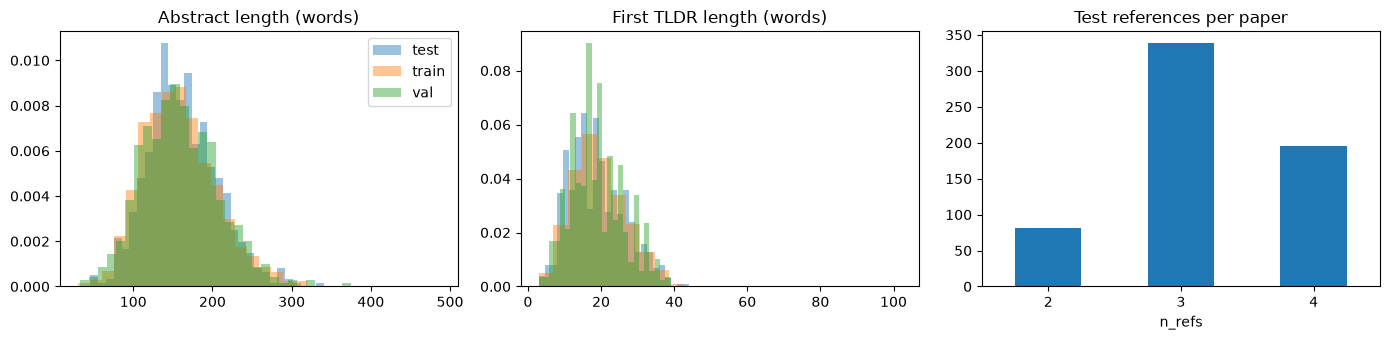

,papers,refs_per_paper_mean,abstract_words_mean,abstract_words_max,first_tldr_words_mean,first_tldr_words_max
split,,,,,,
test,615,3.18,162.20,341,18.89,44
train,1989,1.00,158.77,487,19.28,102
val,617,2.35,159.18,375,18.97,39


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for split, frame in papers.groupby("split"):
    axes[0].hist(frame["abstract_words"], bins=30, alpha=0.45, density=True, label=split)
    axes[1].hist(frame["first_tldr_words"], bins=25, alpha=0.45, density=True, label=split)
axes[0].set_title("Abstract length (words)")
axes[1].set_title("First TLDR length (words)")
axes[0].legend()
papers.loc[papers.split == "test", "n_refs"].value_counts().sort_index().plot.bar(ax=axes[2], rot=0)
axes[2].set_title("Test references per paper")
plt.tight_layout()
plt.show()

display(papers.groupby("split").agg(
    papers=("id", "size"),
    refs_per_paper_mean=("n_refs", "mean"),
    abstract_words_mean=("abstract_words", "mean"),
    abstract_words_max=("abstract_words", "max"),
    first_tldr_words_mean=("first_tldr_words", "mean"),
    first_tldr_words_max=("first_tldr_words", "max")
).round(2))


## 5. Check token truncation against the configured limits

The training notebook truncates abstracts to `max_source_len` and targets to `max_target_len`. Review how many examples would be truncated before training.


In [6]:
tokenizer = AutoTokenizer.from_pretrained(CFG["train"]["model"])
train = papers[papers.split == "train"].copy()

source_lengths = [len(x) for x in tokenizer(train["abstract"].tolist(), truncation=False)["input_ids"]]
target_lengths = [len(x) for x in tokenizer(
    text_target=[refs[0] for refs in train["human_tldrs"]], truncation=False
)["input_ids"]]

length_report = pd.DataFrame({
    "limit": [D["max_source_len"], D["max_target_len"]],
    "max_observed": [max(source_lengths), max(target_lengths)],
    "mean": [sum(source_lengths)/len(source_lengths), sum(target_lengths)/len(target_lengths)],
    "examples_over_limit": [
        sum(x > D["max_source_len"] for x in source_lengths),
        sum(x > D["max_target_len"] for x in target_lengths)
    ]
}, index=["abstract tokens", "target TLDR tokens"])
display(length_report.round(2))


,limit,max_observed,mean,examples_over_limit
abstract tokens,512,616,210.95,2
target TLDR tokens,64,137,27.40,4


## 6. Save processed splits

The JSONL format stores one row per paper and preserves all available TLDR references in `human_tldrs`.


In [7]:
for split in ("train", "val", "test"):
    out = PROC / f"{split}.jsonl"
    papers.loc[papers.split == split, ["id", "abstract", "human_tldrs"]].to_json(
        out, orient="records", lines=True, force_ascii=False
    )
    print(f"{split}: {out} ({(papers.split == split).sum()} papers)")

print("Data preparation complete. Use these processed counts in your report.")


train: c:\Users\admin\Downloads\scitldr-hallucination\scitldr-hallucination\data\processed\train.jsonl (1989 papers)
val: c:\Users\admin\Downloads\scitldr-hallucination\scitldr-hallucination\data\processed\val.jsonl (617 papers)
test: c:\Users\admin\Downloads\scitldr-hallucination\scitldr-hallucination\data\processed\test.jsonl (615 papers)
Data preparation complete. Use these processed counts in your report.
